# Does position change OB sniff-locking? (by behavioral epoch)

Scores come from `position_locking.py` (`python position_locking.py --regions ob --epochs search retrieval`).
Sniffs are restricted to one behavioral epoch at a time - **search** (ITI + search, until the target is found) or
**retrieval** (the find until the first recorded poke) - labeled by `cbmcore.label_epochs`
(`spatial_info.frame_epochs`). A sniff is kept only if its inhalation and the end of its latency window both fall
in the epoch, so consumption/drinking never enters the counts or the null. Spatial info (`ssi`) comes from the matching
`spatial_info_<epoch>.csv`.

Each inhalation is a trial with a latency profile of spikes, a nose position (3 x 7 arena bins; bins with < 100 sniffs
in the epoch are dropped) and a sniff-frequency quintile. Spike counts `C[freq, pos, latency]` are compared against
two models that let position change the unit **without** changing its sniff-locking:

| model | position may change... | residual info = |
|---|---|---|
| separable `O * a[f,p] * b[f,l]` | overall rate (gain) | **interaction**: any change in the latency profile's shape (depth or timing) |
| affine `O * (c[f,p] + g[f,p] * b[f,l])` | rate *and* locking depth (baseline vs locked gain) | **timing**: change in *when* in the sniff it fires (latency shift / width) |

The null swaps spike patterns between sniffs of nearly equal duration from the same quarter of the session (within
the epoch): every sniff keeps its position and duration, so sniff-frequency effects and slow drift are in the null
too, and only the position <-> spike-timing link is broken. `*_frac` = shuffle-corrected bits / sniff-locking bits.

Validated on synthetic units over real sniffs: no effect, pure gain, and latency / width / gain that depend
continuously on sniff duration give |z| < 2; a depth change gives interaction z ~ 43 with timing z < 1; a 5 ms
latency shift gives timing z ~ 6-9 (all sniffs), and a 10 ms shift gives timing z ~ 9-13 on retrieval sniffs alone
(~2,700-2,900 sniffs, under the older and longer retrieval labels).

**Retrieval has almost no power.** Since Nov 23, 2026 the epochs are cbmcore's, and retrieval is about 3 min per
session in bouts of 1-2 s (~800-1,000 sniffs in four sessions checked). Spread over the arena, a median of only 2
position bins per session reach 100 sniffs (299 sniffs in them; before: ~1,600 sniffs in ~10 bins). A session with
fewer than 2 kept bins is not scored, so 82 of 119 sessions and 435 of 1,968 units have retrieval scores, and their
rate of p < 0.05 is at chance (5.1% interaction, 3.7% timing). Read the retrieval columns below as unscored, not as
evidence against position effects.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sys
sys.path.insert(0, 'sniff-raster-python')  # the analysis modules live there
import position_locking as pl
from scipy.ndimage import gaussian_filter1d

EPOCHS = ['search', 'retrieval']
keys = ['mouse', 'session', 'region', 'cluster']
base = pl.OUT_FILE[:-len('.csv')]
sniff_lock = pd.read_csv('E:/cbm-odor/sniff/sniff_locking.csv')
sniff_lock['mouse'] = sniff_lock['mouse'].astype(str)

dfs = {}
for epoch in EPOCHS:
    pos_lock = pd.read_csv(f'{base}_{epoch}.csv')
    space = pd.read_csv(f'E:/cbm-odor/sniff/spatial_info_{epoch}.csv')
    for d in (pos_lock, space):
        d['mouse'] = d['mouse'].astype(str)
    df = (pos_lock
          .merge(sniff_lock[keys + ['info_z', 'info_p', 'peak_latency_ms']], on=keys, how='left', validate='one_to_one')
          .merge(space[keys + ['ssi', 'p_empirical']], on=keys, how='left', validate='one_to_one'))
    df = df[df['timing_z'].notna()].copy()
    df['sniff_locked'] = df['info_p'] < 0.05  # whole-session sniff locking
    df['place_tuned'] = df['p_empirical'] < 0.05  # within this epoch
    df['sig_interaction'] = df['interaction_p'] < 0.01
    df['sig_timing'] = df['timing_p'] < 0.01
    dfs[epoch] = df

# With a perfect null, median z ~ 0 and ~1% of units pass p < 0.01. Non-locked units can still have real
# position-dependent locking, so their pass rate is only an upper bound on the false-positive rate.
summary = pd.concat({e: d.groupby('sniff_locked').agg(
    n_units=('cluster', 'size'), median_sniffs=('n_sniffs', 'median'), median_pos_bins=('n_pos_bins', 'median'),
    frac_sig_interaction=('sig_interaction', 'mean'), frac_sig_timing=('sig_timing', 'mean'),
    median_interaction_z=('interaction_z', 'median'), median_timing_z=('timing_z', 'median'))
    for e, d in dfs.items()})
display(summary.round(3))

n_units  median_sniffs  median_pos_bins  \
          sniff_locked                                            
search    False             308        13464.0             21.0   
          True             1647        14642.0             21.0   
retrieval False              76          517.0              3.0   
          True              359          483.0              3.0   

                        frac_sig_interaction  frac_sig_timing  \
          sniff_locked                                          
search    False                        0.058            0.036   
          True                         0.200            0.109   
retrieval False                        0.013            0.013   
          True                         0.003            0.008   

                        median_interaction_z  median_timing_z  
          sniff_locked                                         
search    False                        0.323            0.238  
          True                         0.932            0.557  
retrieval False                       -0.226           -0.267  
          True                         0.016           -0.045

## Distributions (sniff-locked units)

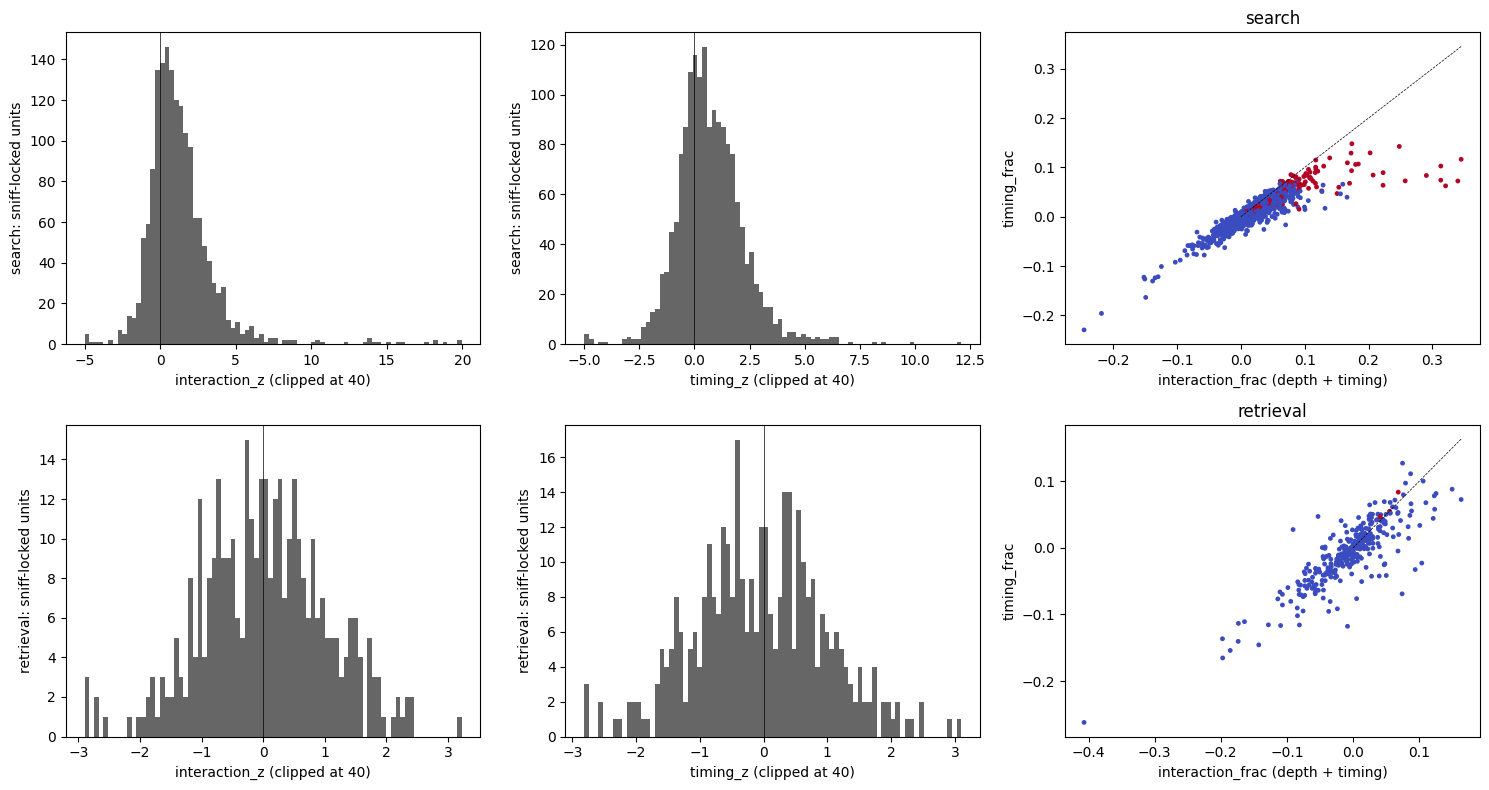

In [2]:
fig, axes = plt.subplots(len(EPOCHS), 3, figsize=(15, 4 * len(EPOCHS)))
for row, epoch in zip(axes, EPOCHS):
    locked = dfs[epoch][dfs[epoch]['sniff_locked']]
    for ax, col in zip(row[:2], ['interaction_z', 'timing_z']):
        ax.hist(np.clip(locked[col], -5, 40), bins=80, color='0.4')
        ax.axvline(0, color='k', lw=0.5)
        ax.set_xlabel(col + ' (clipped at 40)')
        ax.set_ylabel(f'{epoch}: sniff-locked units')
    ax = row[2]
    ax.scatter(locked['interaction_frac'], locked['timing_frac'], s=6, c=locked['sig_timing'], cmap='coolwarm')
    lim = locked['interaction_frac'].max()
    ax.plot([0, lim], [0, lim], 'k--', lw=0.5)
    ax.set_xlabel('interaction_frac (depth + timing)')
    ax.set_ylabel('timing_frac')
    ax.set_title(epoch)
plt.tight_layout()
plt.show()

## Search vs retrieval

Same unit, both epochs. Units significant in both have position-dependent timing that holds across behavioral states;
units significant in only one are candidates for epoch-specific effects (keeping in mind the retrieval epoch has
much less power, so "search only" is often just a missed detection). With cbmcore's labels only 359 sniff-locked units
are scored in both epochs and the retrieval scores are at chance, so this comparison cannot show epoch-specific
effects.

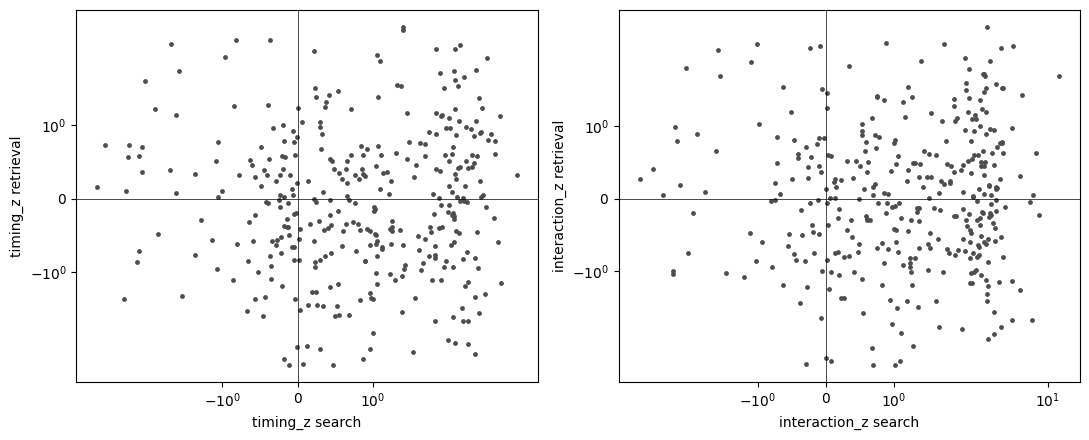

359 sniff-locked units scored in both epochs; rank correlation of timing_z: 0.06


timing sig (retrieval),False,True,All
timing sig (search),,,
False,304,3,307
True,52,0,52
All,356,3,359


In [3]:
both = dfs['search'].merge(dfs['retrieval'], on=keys, suffixes=('_app', '_con'))
both = both[both['sniff_locked_app']]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col in zip(axes, ['timing_z', 'interaction_z']):
    ax.scatter(both[f'{col}_app'], both[f'{col}_con'], s=6, c='0.3')
    ax.set_xscale('symlog'); ax.set_yscale('symlog')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.set_xlabel(f'{col} search'); ax.set_ylabel(f'{col} retrieval')
plt.tight_layout()
plt.show()
print(f"{len(both)} sniff-locked units scored in both epochs; rank correlation of timing_z: "
      f"{both['timing_z_app'].corr(both['timing_z_con'], method='spearman'):.2f}")
display(pd.crosstab(both['sig_timing_app'].rename('timing sig (search)'),
                    both['sig_timing_con'].rename('timing sig (retrieval)'), margins=True))

## Position-dependent locking vs place tuning (within each epoch)

search


sig_timing,False,True,All
place_tuned,,,
False,203,12,215
True,1265,167,1432
All,1468,179,1647


retrieval


sig_timing,False,True,All
place_tuned,,,
False,67,2,69
True,289,1,290
All,356,3,359


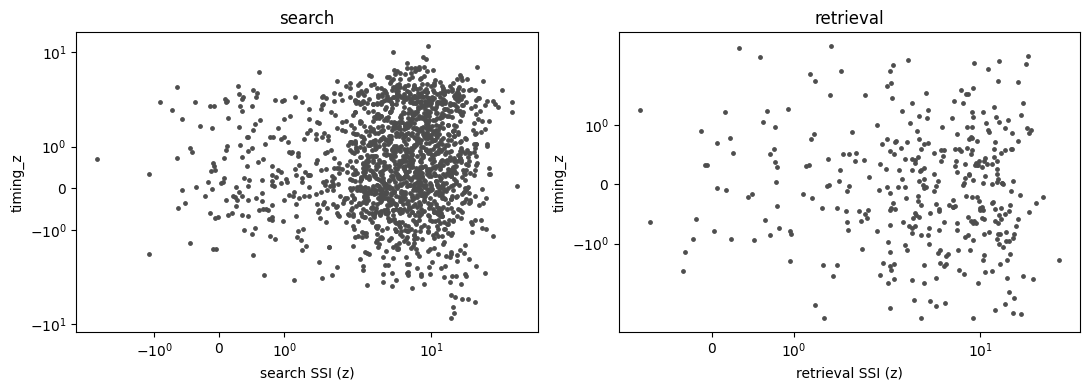

In [4]:
fig, axes = plt.subplots(1, len(EPOCHS), figsize=(5.5 * len(EPOCHS), 4))
for ax, epoch in zip(axes, EPOCHS):
    locked = dfs[epoch][dfs[epoch]['sniff_locked']]
    ax.scatter(locked['ssi'], locked['timing_z'], s=6, c='0.3')
    ax.set_xscale('symlog'); ax.set_yscale('symlog')
    ax.set_xlabel(f'{epoch} SSI (z)'); ax.set_ylabel('timing_z'); ax.set_title(epoch)
    print(epoch); display(pd.crosstab(locked['place_tuned'], locked['sig_timing'], margins=True))
plt.tight_layout()
plt.show()

## Top units per epoch: position changes *when* in the sniff they fire

In [5]:
MIN_SPIKES_RANK = 2000  # spikes inside the epoch's sniff windows
cols = keys + ['group', 'n_sniffs', 'n_pos_bins', 'n_spikes_used', 'info_z', 'ssi', 'lock_bits_per_spike',
               'interaction_z', 'timing_z', 'timing_corrected', 'timing_frac']
top = {}
for epoch in EPOCHS:
    locked = dfs[epoch][dfs[epoch]['sniff_locked']]
    # ranked by corrected bits/spike so weakly locked units with a large fraction don't dominate
    top[epoch] = locked[locked['sig_timing'] & (locked['n_spikes_used'] >= MIN_SPIKES_RANK)].sort_values(
        'timing_corrected', ascending=False)
    print(epoch)
    display(top[epoch][cols].head(15))

search


,mouse,session,region,cluster,group,n_sniffs,n_pos_bins,n_spikes_used,info_z,ssi,lock_bits_per_spike,interaction_z,timing_z,timing_corrected,timing_frac
123,9000,x11,ob,14,mua,13846,21,6495,2.966242,10.457252,0.251393,2.661817,2.492132,0.016971,0.067506
393,9002,x4,ob,1,mua,12997,21,8511,2.208097,1.860002,0.183151,3.139597,2.795897,0.013957,0.076204
823,9005,x3,ob,17,mua,15075,21,10428,53.766045,6.242483,0.187739,4.199784,3.075017,0.013290,0.070787
241,9002,o2,ob,13,mua,12075,21,9707,4.618587,15.751965,0.182950,2.630783,2.664726,0.013058,0.071375
464,9002,x9,ob,29,mua,15136,21,7757,14.048029,5.877181,0.184519,2.944268,2.567281,0.012578,0.068166
1810,9009,t5,ob,3,mua,15349,21,10978,399.142045,4.449120,0.640934,3.528595,3.858809,0.011716,0.018280
1039,9006,t5,ob,37,mua,16148,21,8032,3.667374,10.191517,0.167396,2.379607,2.334369,0.011162,0.066680
793,9005,x11,ob,15,mua,14127,21,41901,142.999323,9.392830,0.116568,19.837099,12.109208,0.010880,0.093334
983,9006,t2,ob,44,mua,15708,21,9614,11.683649,2.348258,0.150305,2.160840,2.722046,0.010833,0.072073
792,9005,x11,ob,14,mua,14127,21,22523,56.407474,7.810134,0.126704,14.340649,6.409237,0.010698,0.084434


retrieval


,mouse,session,region,cluster,group,n_sniffs,n_pos_bins,n_spikes_used,info_z,ssi,lock_bits_per_spike,interaction_z,timing_z,timing_corrected,timing_frac
256,9002,o3,ob,3,mua,6511,15,2837.0,9.801427,1.453694,0.353704,2.366612,3.102537,0.029654,0.083839


## Unit viewer

`plot_unit(mouse, session, cluster, epoch)` uses only that epoch's sniffs. Top row: rate vs latency for each position bin
(rows, ordered along the arena's long axis), one panel per sniff-frequency quintile, each row normalized to its max
(smoothed over 1 latency bin; bins less than half-covered by the sniffs are blank). Bottom row: arena maps of latency
shift (response centroid in the first 90 ms vs the other positions), rate, and locking depth (1 - min/max of the
latency profile), pooled over frequency. Position bins with too few sniffs in the epoch are blank.

In [6]:
def plot_unit(mouse, session, cluster, epoch, region='ob'):
    mouse = str(mouse)
    units, spike_times, clusters = pl.load_units(mouse, session, region)
    last = (int(spike_times[-1]) + 15) // 30
    sess = pl.Session(mouse, session, last_ms=last, n_shuffle=0, epoch=epoch)
    spikes = spike_times[clusters == cluster].astype(float) / 30
    C, O = sess.counts(*sess.unit(spikes)).astype(float), sess.O
    Cs, Os = gaussian_filter1d(C, 1, axis=-1), gaussian_filter1d(O, 1, axis=-1)
    with np.errstate(divide='ignore', invalid='ignore'):
        rate = np.where(O >= 0.5 * O[..., :1], 1e3 * Cs / Os, np.nan)  # Hz, (F, P, L); drop partial bins
        rate_p = np.where(O.sum(0) >= 0.5 * O.sum(0)[:, :1], 1e3 * Cs.sum(0) / Os.sum(0), np.nan)
    lat = sess.lat_edges[:-1] + pl.LAT_BIN_MS / 2
    ix, iy = np.divmod(sess.pos_bins, sess.ny)
    order = np.lexsort((ix, iy))  # along the long (y) axis

    fig = plt.figure(figsize=(16, 9))
    gs = fig.add_gridspec(2, 3 * pl.N_FREQ)
    for f in range(pl.N_FREQ):
        ax = fig.add_subplot(gs[0, 3 * f:3 * f + 3])
        r = rate[f][order]
        with np.errstate(divide='ignore', invalid='ignore'):
            ax.imshow(r / np.nanmax(r, 1, keepdims=True), aspect='auto', cmap='viridis', vmin=0, vmax=1,
                      extent=[0, pl.WINDOW_MS, len(order), 0], interpolation='nearest')
        ax.set_yticks(np.arange(len(order)) + 0.5, [f'({ix[o]},{iy[o]})' for o in order], fontsize=6)
        lo, hi = sess.freq_edges[f], sess.freq_edges[f + 1]
        ax.set_title(f'{lo:.1f}-{hi:.1f} Hz sniffs')
        ax.set_xlabel('latency from inhalation (ms)')
    fig.axes[0].set_ylabel('position bin (x, y)')

    peak = np.full((sess.nx, sess.ny), np.nan)
    mean_rate, depth = peak.copy(), peak.copy()
    # latency centroid of the above-baseline response in the first 90 ms (covered at every sniff rate), relative to
    # the mean over positions within each frequency stratum, then averaged over strata weighted by spikes
    with np.errstate(divide='ignore', invalid='ignore'):
        above = np.where(lat < 90, rate - np.nanmin(rate, -1, keepdims=True), np.nan)
        centroid = np.nansum(above * lat, -1) / np.nansum(above, -1)  # (F, P)
        shift = centroid - np.nanmean(centroid, 1, keepdims=True)
        w = np.where(np.isnan(shift), 0, C.sum(-1))
        peak[ix, iy] = np.nansum(shift * w, 0) / w.sum(0)
        mean_rate[ix, iy] = 1e3 * C.sum((0, 2)) / O.sum((0, 2))
        depth[ix, iy] = 1 - np.nanmin(rate_p, 1) / np.nanmax(rate_p, 1)
    lim = np.nanmax(np.abs(peak))
    for i, (m, title, cmap) in enumerate([(peak, 'latency shift vs other positions (ms)', 'coolwarm'),
                                          (mean_rate, 'rate in window (Hz)', 'magma'),
                                          (depth, 'locking depth', 'cividis')]):
        ax = fig.add_subplot(gs[1, i * pl.N_FREQ:(i + 1) * pl.N_FREQ])
        im = ax.imshow(m.T, cmap=cmap, **(dict(vmin=-lim, vmax=lim) if i == 0 else {}),
                       extent=[*pl.ARENA_X_RANGE_PX, pl.ARENA_Y_RANGE_PX[1], pl.ARENA_Y_RANGE_PX[0]])
        fig.colorbar(im, ax=ax, label=title)
        ax.set_title(title)
    d = dfs[epoch]
    row = d[(d['mouse'] == mouse) & (d['session'] == session) & (d['cluster'] == cluster)]
    stats = '' if row.empty else (f"  |  timing z={row['timing_z'].iat[0]:.1f}, frac={row['timing_frac'].iat[0]:.3f}"
                                  f"  |  interaction z={row['interaction_z'].iat[0]:.1f}")
    fig.suptitle(f'{mouse} {session} {region} cl {cluster}  [{epoch}, {sess.locs.size} sniffs]{stats}')
    plt.tight_layout()
    plt.show()

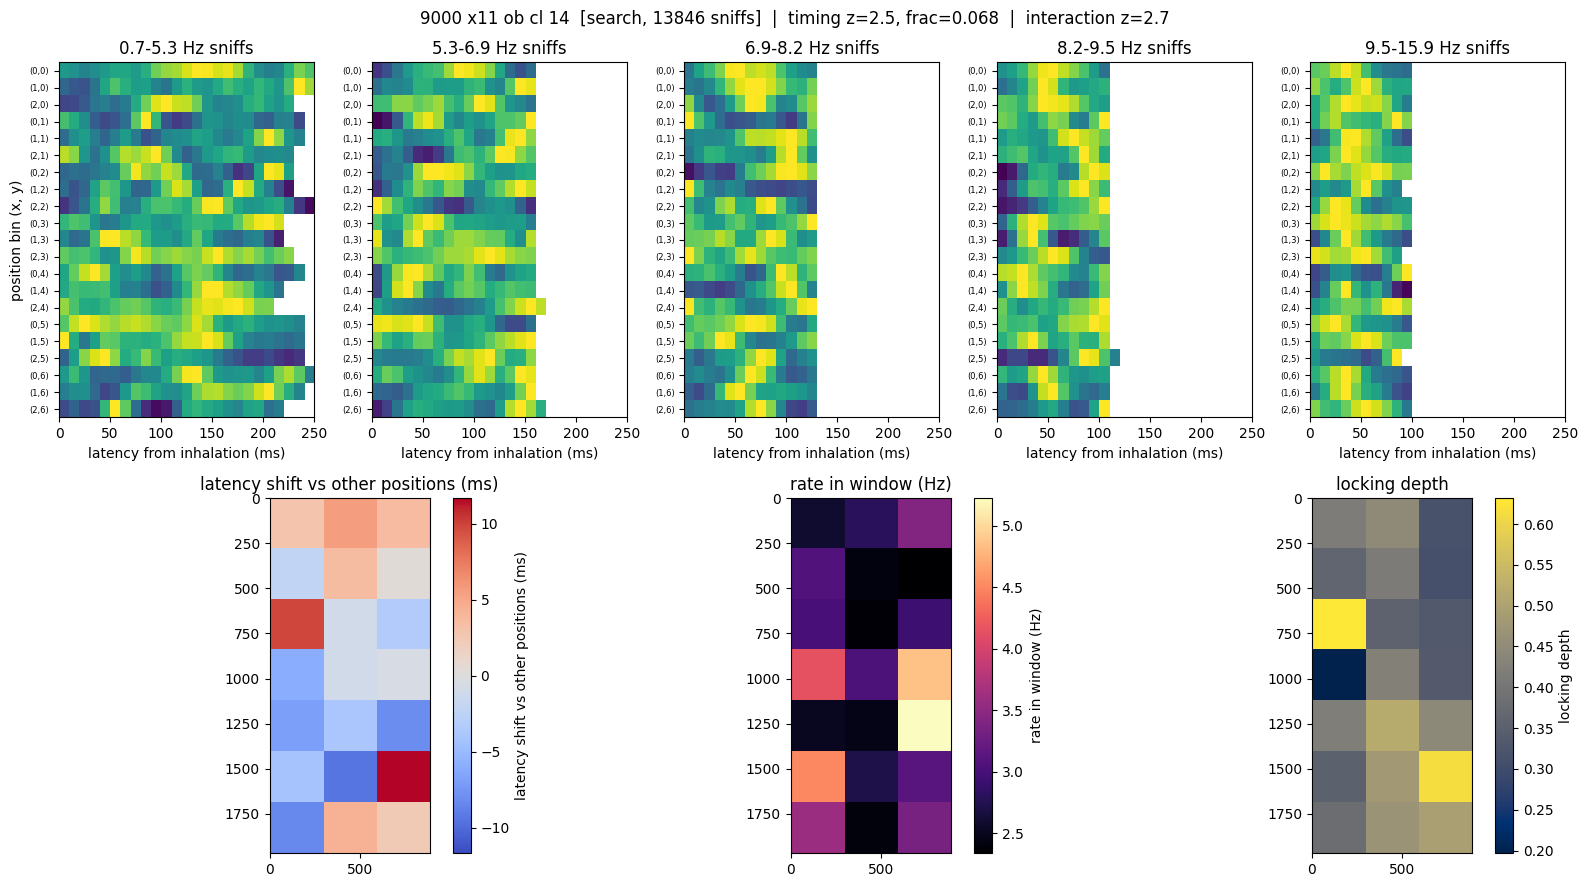

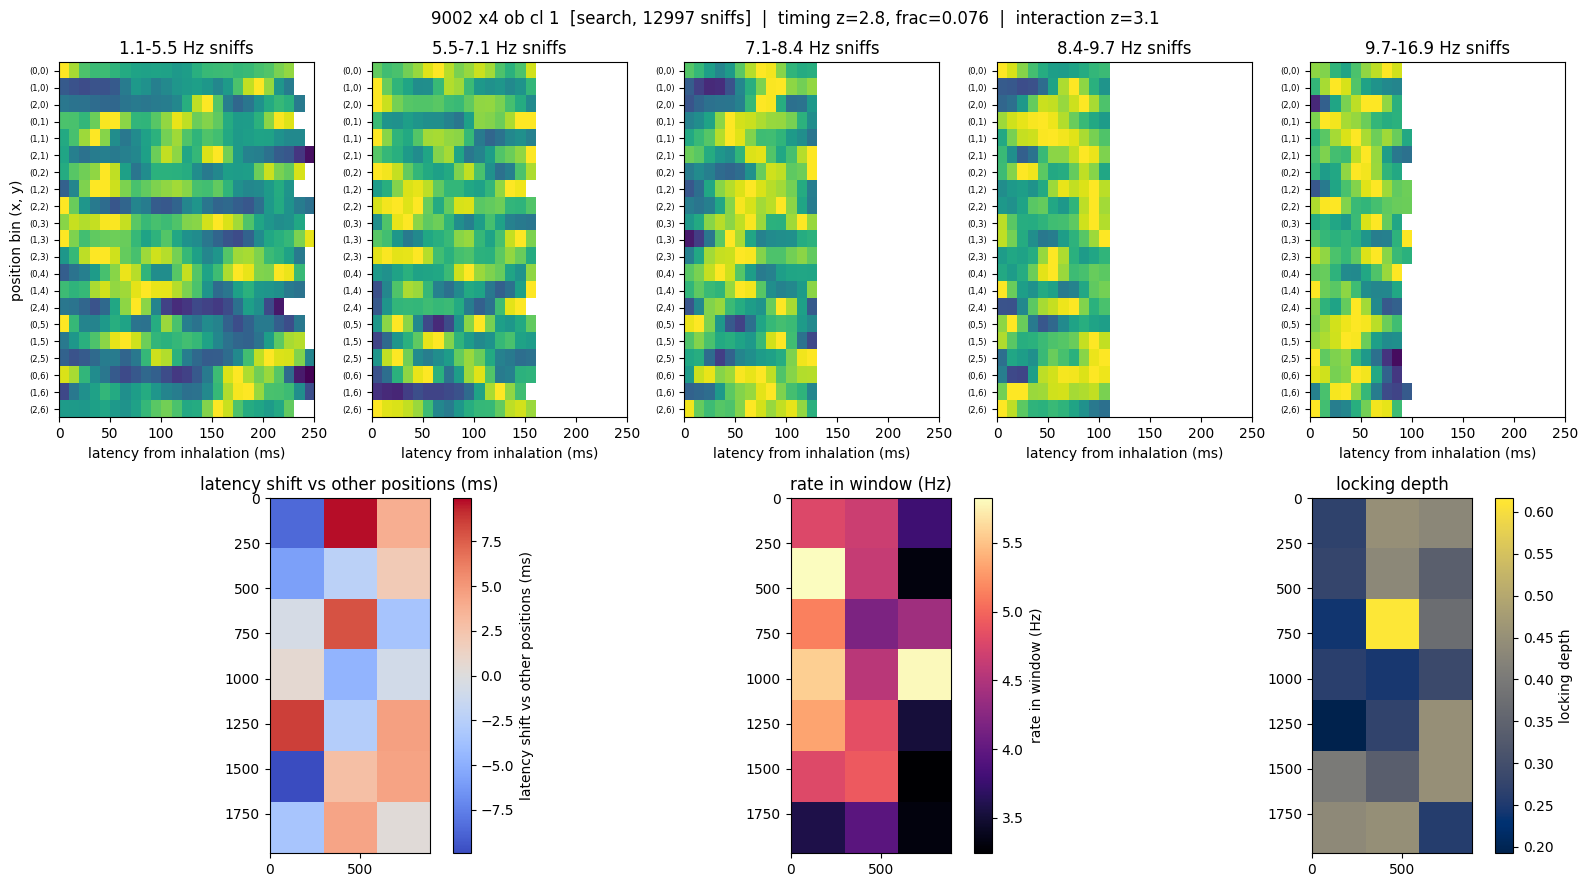

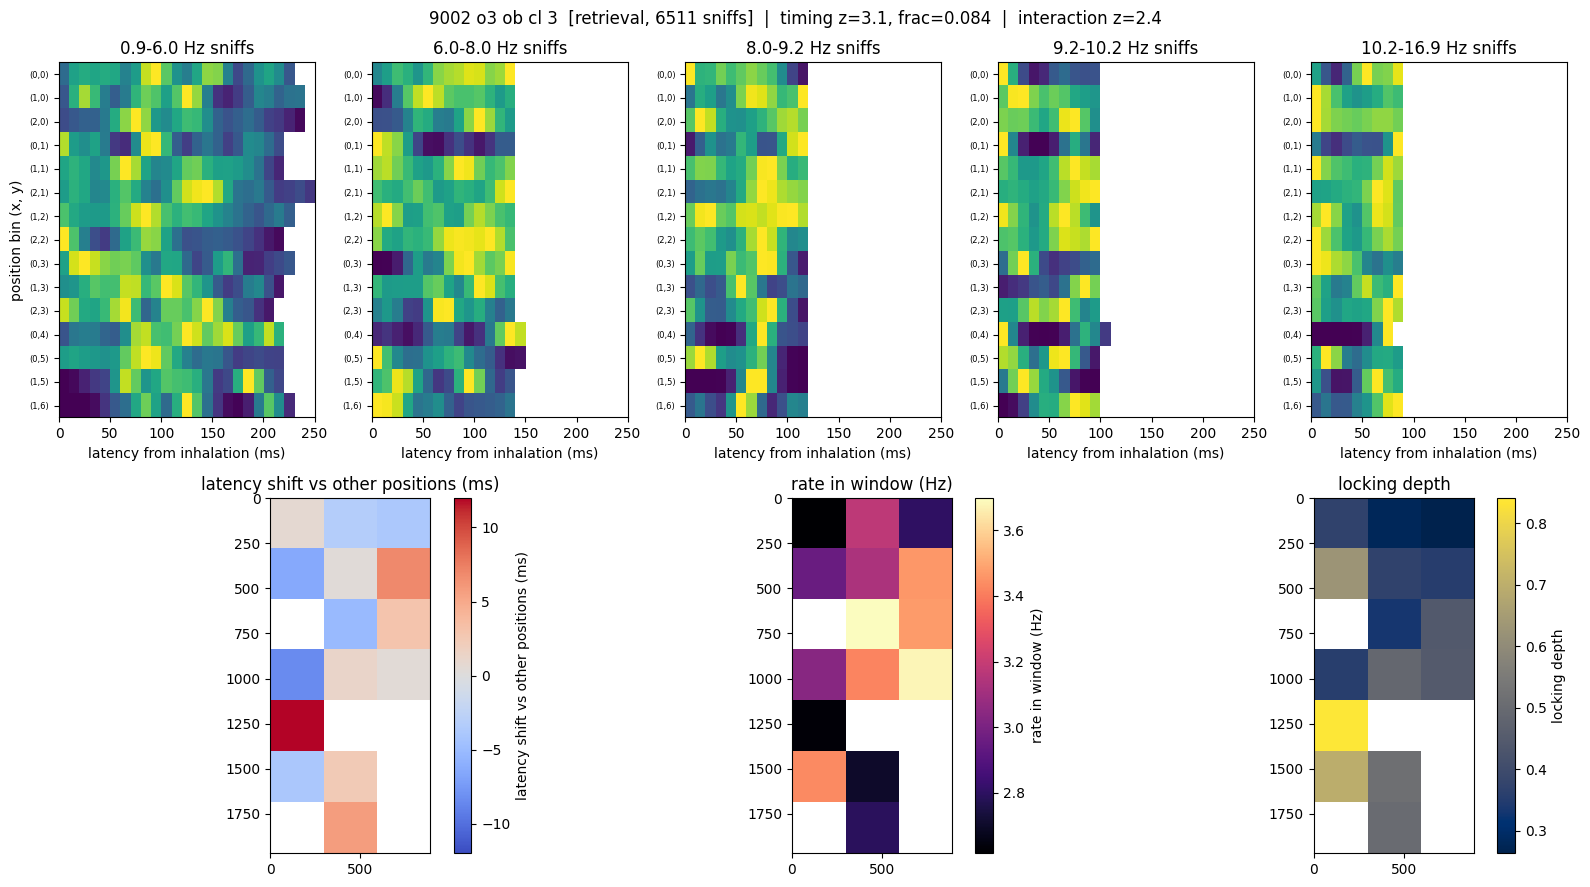

In [7]:
for epoch in EPOCHS:
    for _, u in top[epoch].head(2).iterrows():
        plot_unit(u['mouse'], u['session'], u['cluster'], epoch)

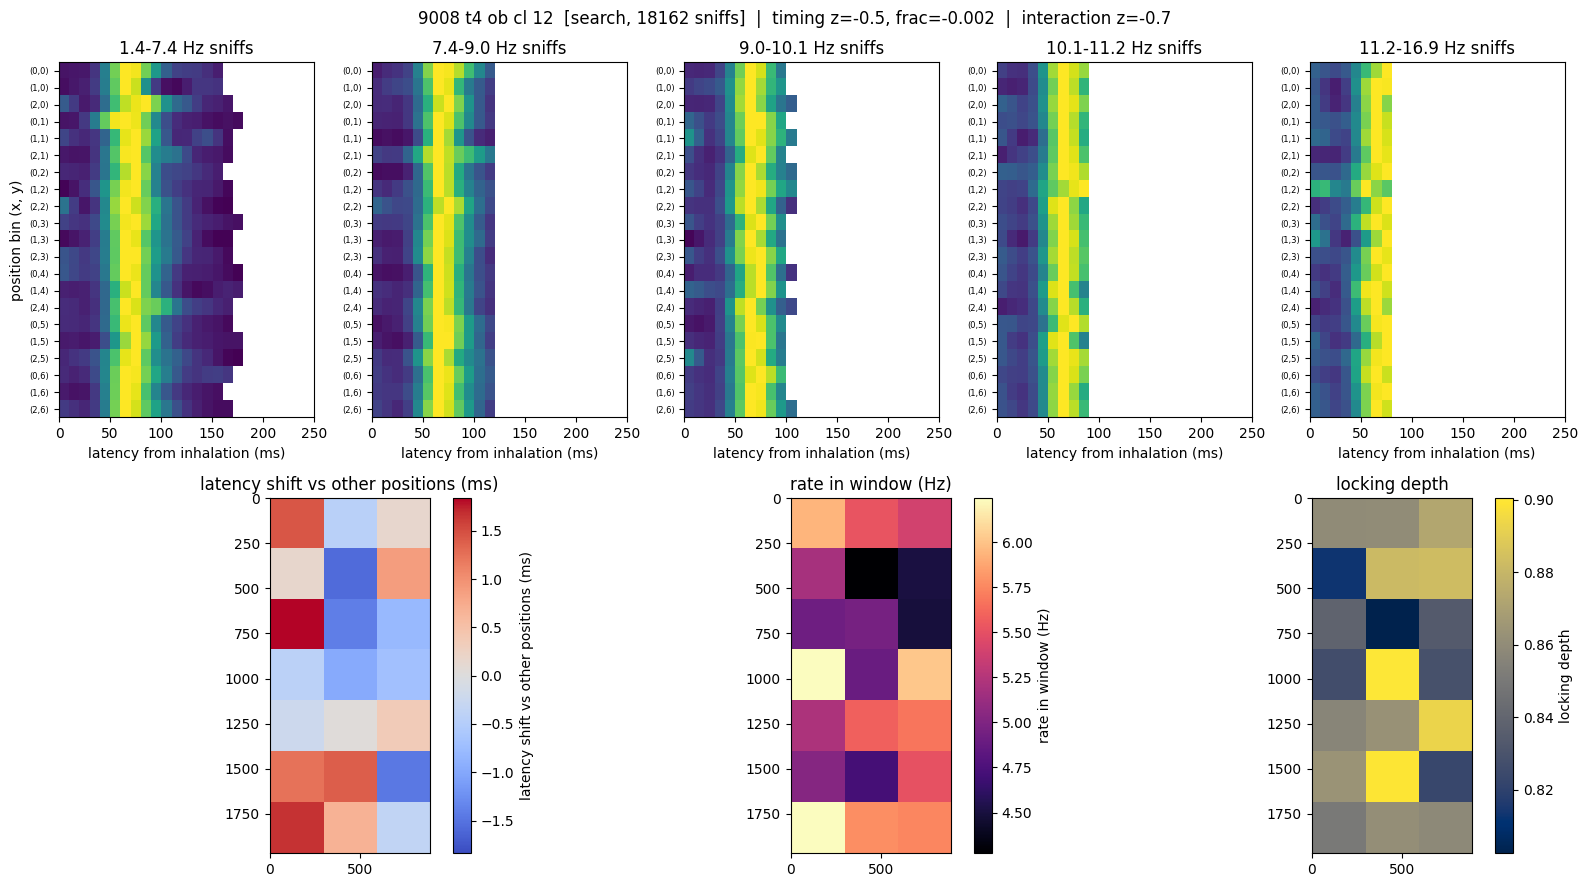

In [8]:
# a strongly sniff-locked unit whose search locking does NOT depend on position, for comparison
locked = dfs['search'][dfs['search']['sniff_locked']]
stable = locked[locked['info_z'] > locked['info_z'].quantile(0.9)].sort_values('interaction_z').iloc[0]
plot_unit(stable['mouse'], stable['session'], stable['cluster'], 'search')

## High-interaction units split by trial flip state

The units with the highest search `interaction_z`, split by `flip_state` (0/1/2, constant within a trial) as in
cluster-states-viewer's Flip State tab - search epoch only, each state normalized by its own occupancy. Top row:
place rate map per flip state (the model's 3 x 7 position bins, shared color scale) and the sniff-latency profile of
each state. Bottom row: latency profile by position along the arena's long (y) axis for each state (rows normalized to
their max), and each state's latency profile minus the mean of the three, with a 95% CI from resampling that state's
trials (1000 bootstraps).

The plotting code lives in `flip_state_plots.py`. `python flip_state_plots.py` saves a PNG for every scored unit to
`E:/cbm-odor/sniff/flip_state_png/<region>/<mouse>/<session>/`, named
`<interaction_z>_<mouse>_<session>_<region>_cl<cluster>_<epoch>.png`.

The latency profiles pool all sniff frequencies, so a flip state in which the animal sniffs faster or slower can
differ here without any change in locking; treat differences as leads to test, not results.

,mouse,session,region,cluster,group,n_sniffs,n_pos_bins,n_spikes_used,info_z,ssi,lock_bits_per_spike,interaction_z,timing_z,timing_corrected,timing_frac
821,9005,x3,ob,11,mua,15075,21,37742,43.559069,6.161940,0.085424,19.954992,6.156004,0.006186,0.072420
793,9005,x11,ob,15,mua,14127,21,41901,142.999323,9.392830,0.116568,19.837099,12.109208,0.010880,0.093334
844,9005,x4,ob,23,good,14533,21,54398,354.818233,15.186754,0.133314,18.780804,3.902071,0.002031,0.015232
831,9005,x3,ob,26,mua,15075,21,50337,19.967850,9.019135,0.061353,18.331541,8.131198,0.007143,0.116429
822,9005,x3,ob,14,mua,15075,21,47237,28.471902,6.653565,0.061827,18.121650,5.365250,0.003870,0.062589


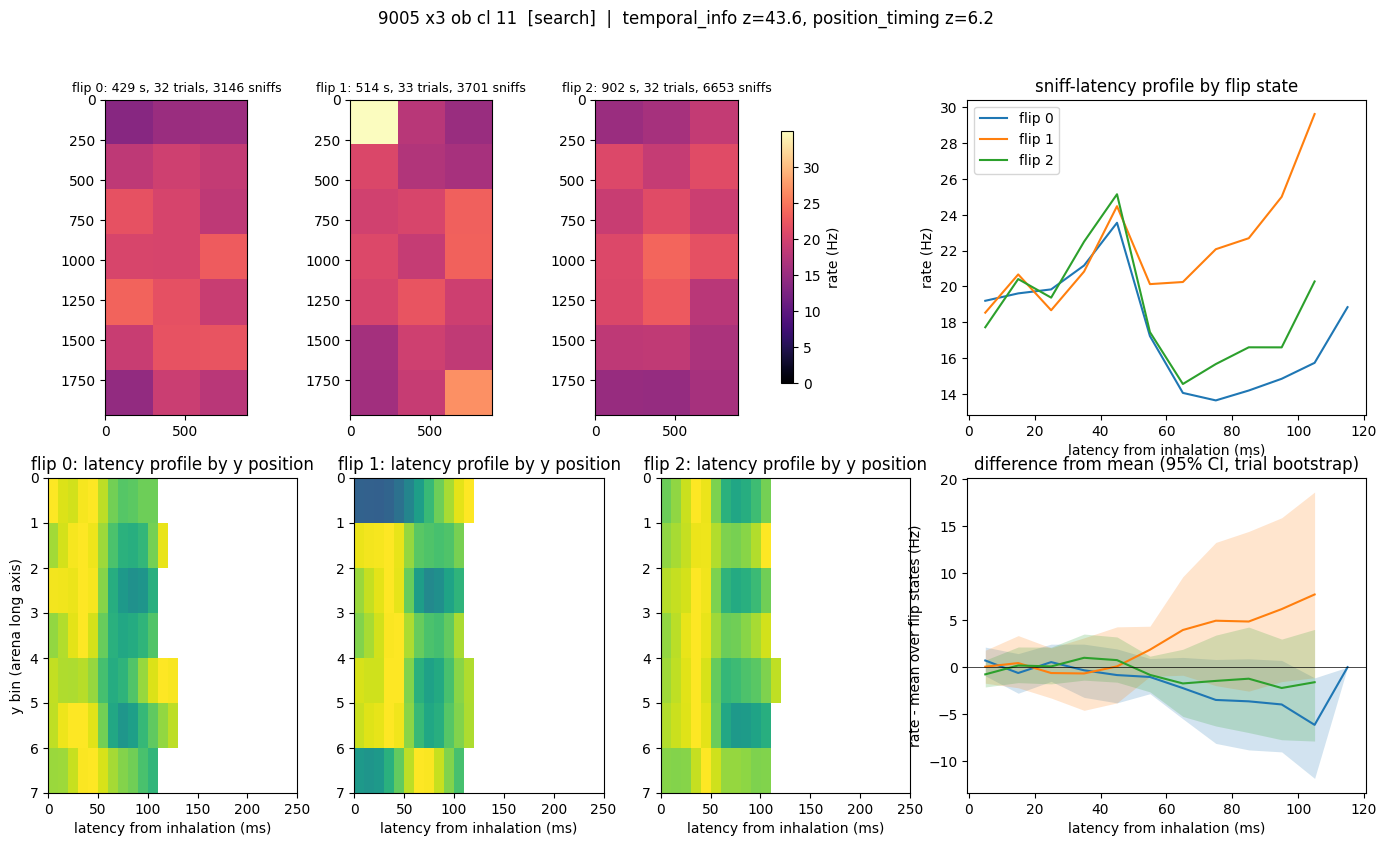

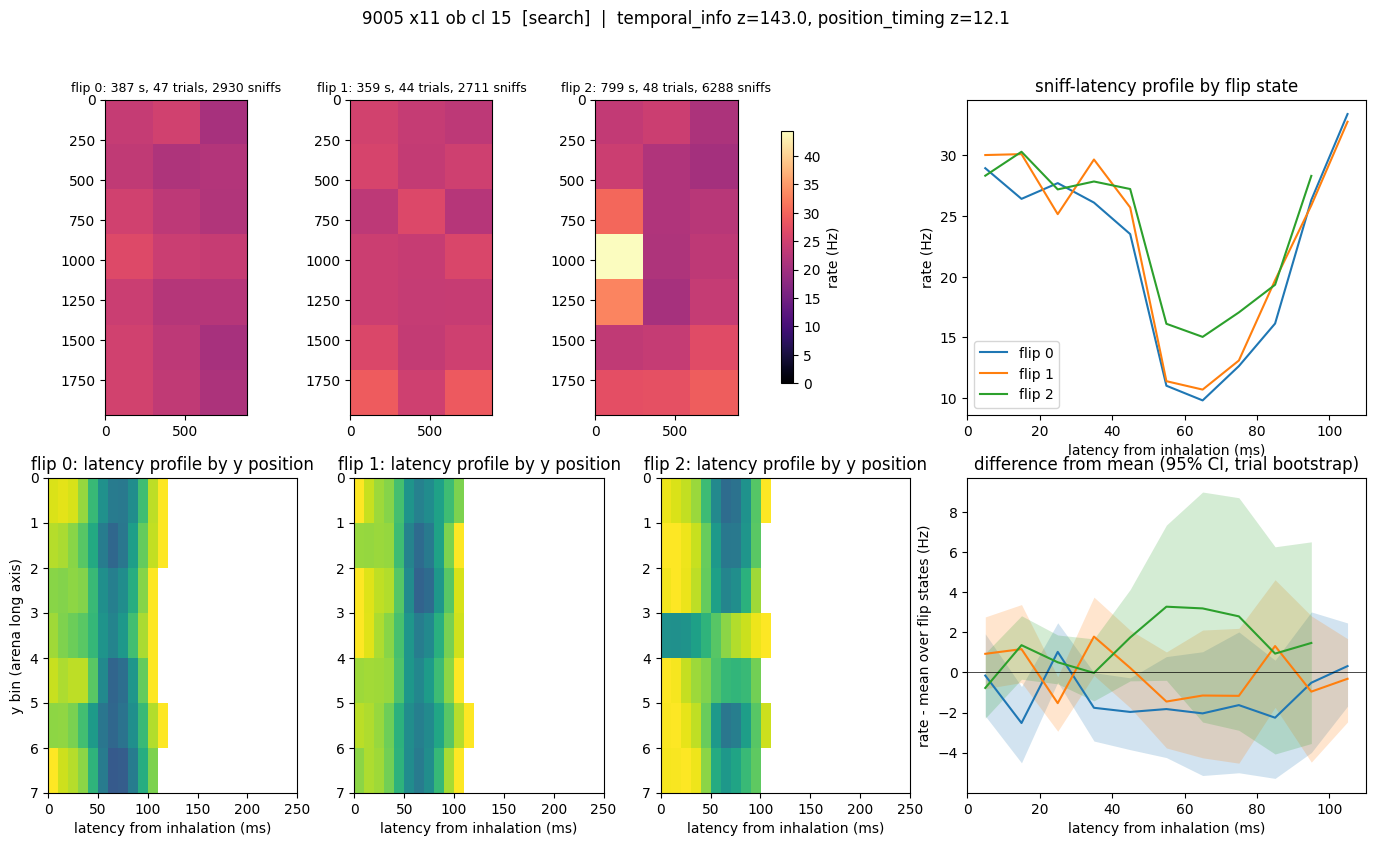

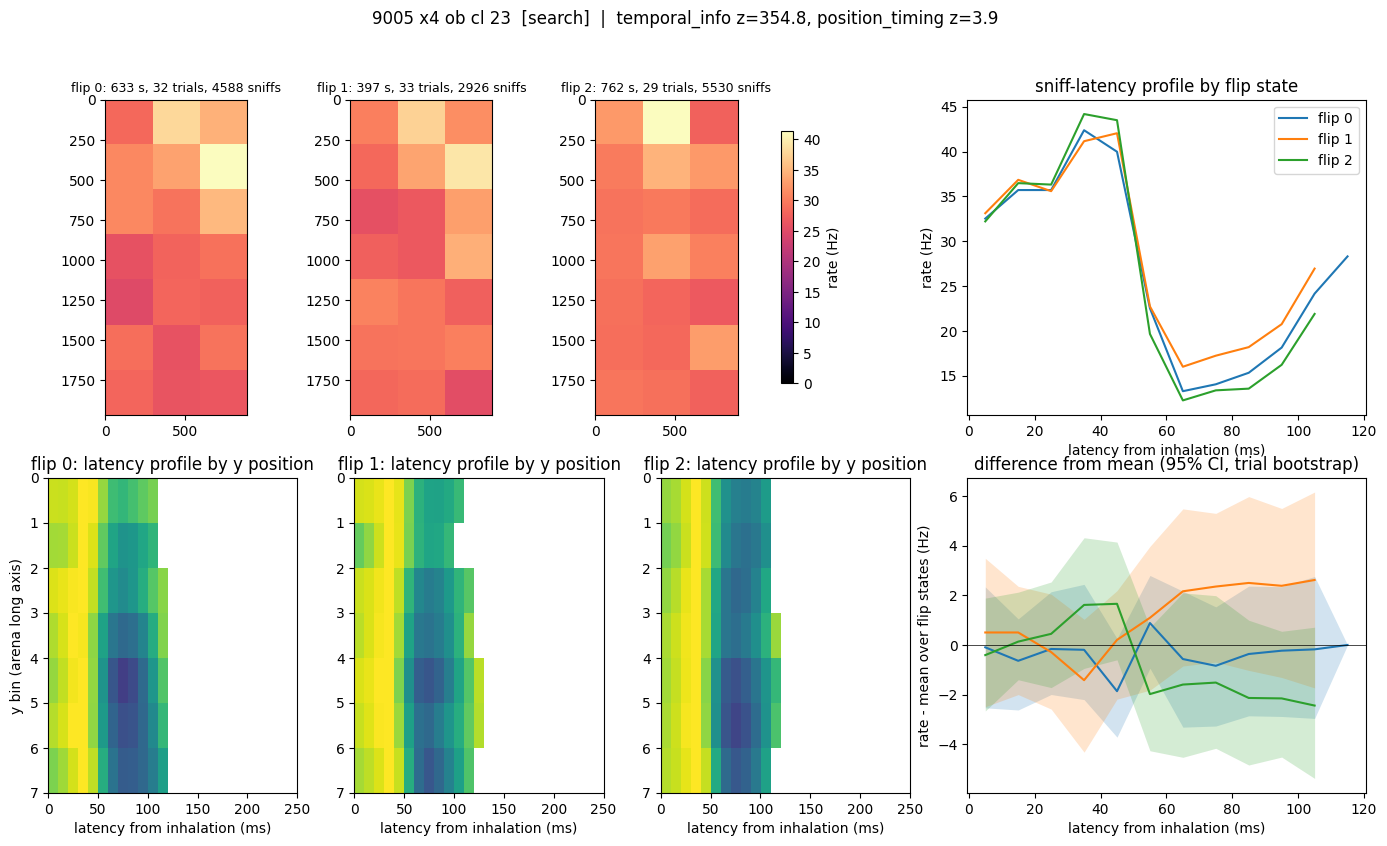

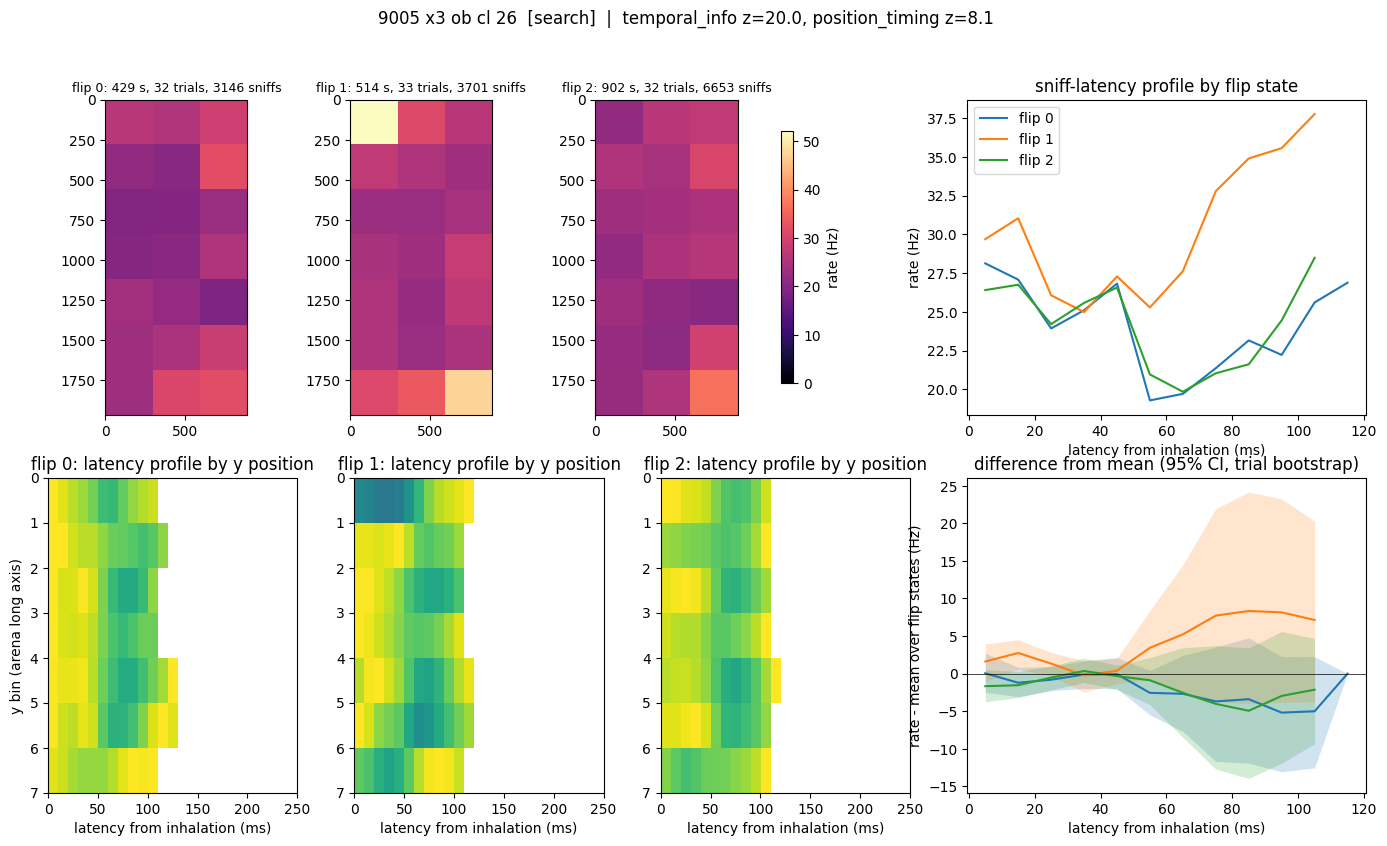

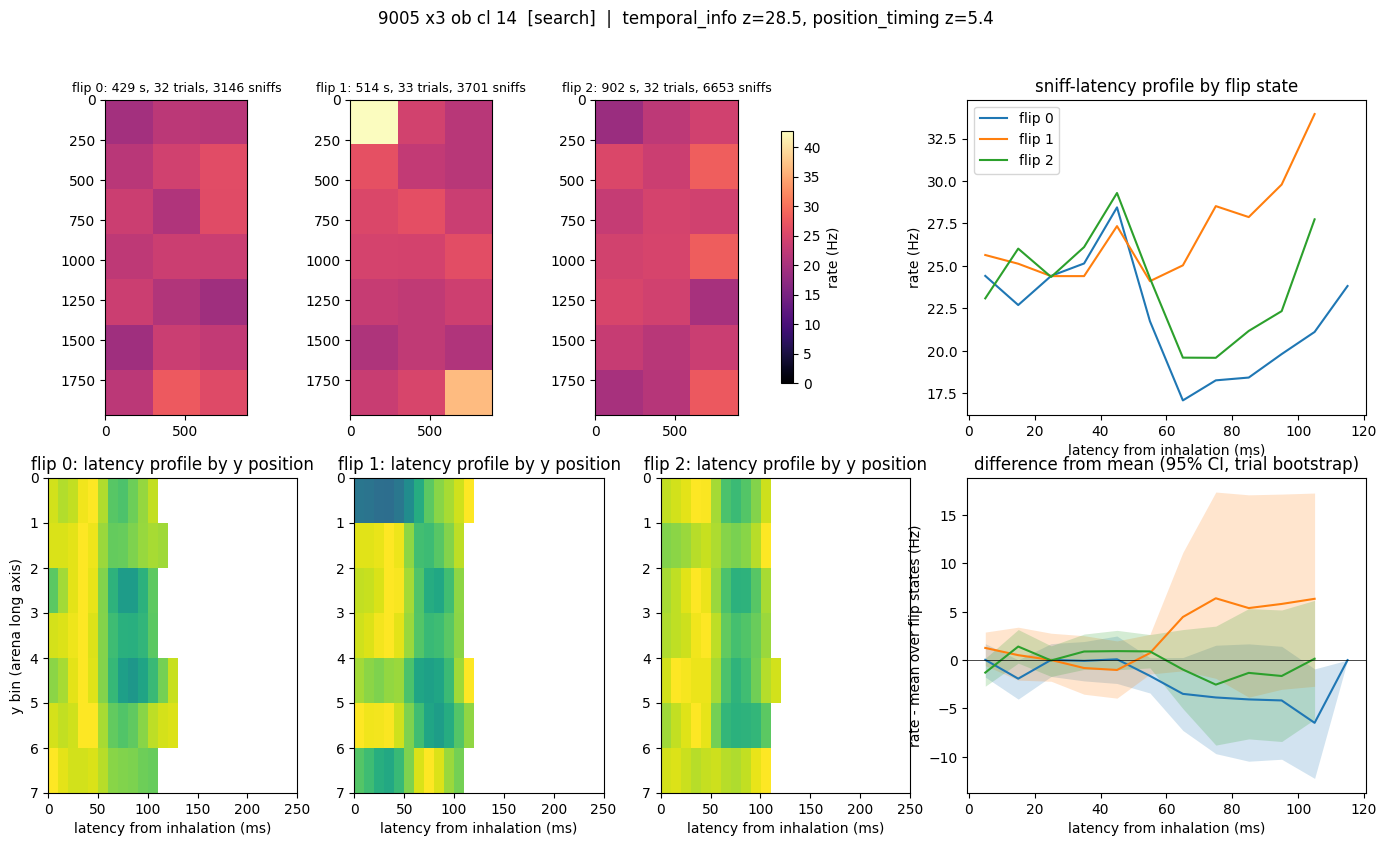

In [9]:
from flip_state_plots import FlipSession, PNG_DIR

N_UNITS = 5
SAVE_PNGS = False  # True also writes the figure to PNG_DIR/<region>/<mouse>/<session>/


def plot_flip_states(mouse, session, cluster, epoch='search', region='ob'):
    """One unit split by trial flip_state within one epoch (see flip_state_plots.py)."""
    d = dfs[epoch]
    row = d[(d['mouse'] == str(mouse)) & (d['session'] == session) & (d['cluster'] == cluster)]
    iz, tz, info_z = (None,) * 3 if row.empty else (row[c].iat[0] for c in ['interaction_z', 'timing_z', 'info_z'])
    # the title shows temporal_info z (whole-session sniff locking, info_z) and position_timing z (timing_z)
    FlipSession(mouse, session, epoch, region).plot(cluster, iz, tz, save_dir=PNG_DIR if SAVE_PNGS else None, info_z=info_z)


locked = dfs['search'][dfs['search']['sniff_locked']]
top_interaction = locked[locked['n_spikes_used'] >= MIN_SPIKES_RANK].sort_values('interaction_z', ascending=False)
display(top_interaction[cols].head(N_UNITS))
for _, u in top_interaction.head(N_UNITS).iterrows():
    plot_flip_states(u['mouse'], u['session'], u['cluster'])